Case A :
Deteksi penipuan pembukaan rekening bank

Sebuah bank digital menerima ribuan pengajuan buka rekening online setiap hari. Sebagian kecil diajukan penipu, misalnya dengan identitas palsu atau untuk menampung uang hasil kejahatan. Tim risiko ingin setiap pengajuan baru diberi skor: seberapa mungkin pengajuan ini penipuan

Data: Bank Account Fraud (BAF) varian base, bulan 0-3. Satu baris = satu pengajuan, dengan satu kolom label penipuan
Tujuan: tangkap sebanyak mungkin penipu, dengan syarat nasabah jujur yang ikut tertandai paling banyak 5%. Setiap nasabah jujur yang tertandai berarti calon pelanggan hilang dan tambahan kerja verifikasi manual
Angka yang dilaporkan: persentase penipu yang tertangkap saat nasabah jujur yang salah tertandai dibatasi 5% (TPR pada FPR 5%)

Nama : Ilham Notohusodo

NIM  : 24120500018


In [29]:
import kagglehub
import os
import pandas as pd

In [30]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

In [31]:
warnings.filterwarnings("ignore", category=FutureWarning)


In [32]:
# ---------- Konfigurasi ----------
TARGET_FPR = 0.05          # batas nasabah jujur yang boleh tertandai
SEED = 42
TRAIN_MONTHS = [0, 1]      # latih
VAL_MONTHS = [2]           # validasi: pilih model + threshold
TEST_MONTHS = [3]          # uji akhir: tidak dipakai untuk memilih apa pun
DROP_COLS = []
OUT_DIR = Path("model")
OUT_DIR.mkdir(exist_ok=True)

CAT_COLS = ["payment_type", "employment_status", "housing_status", "source", "device_os"]
# Kolom yang memakai -1 sebagai penanda "data hilang" (menurut datasheet BAF).
# credit_risk_score sengaja TIDAK ada di sini: nilai negatif di sana sah.


### 1. Load Data

In [33]:
path = kagglehub.dataset_download("sgpjesus/bank-account-fraud-dataset-neurips-2022")
print("Daftar file tersedia:", os.listdir(path))

Using Colab cache for faster access to the 'bank-account-fraud-dataset-neurips-2022' dataset.
Daftar file tersedia: ['Base.csv', 'Variant IV.csv', 'Variant V.csv', 'Variant I.csv', 'Variant III.csv', 'Variant II.csv']


In [34]:
file_path = os.path.join(path, "Base.csv")
df = pd.read_csv(file_path)
pd.set_option("display.max_columns", None)
df.head(10)

print("Ukuran dataset (baris, kolom):", df.shape)
df.head(10)

Ukuran dataset (baris, kolom): (1000000, 32)


,fraud_bool,income,name_email_similarity,prev_address_months_count,current_address_months_count,customer_age,days_since_request,intended_balcon_amount,payment_type,zip_count_4w,velocity_6h,velocity_24h,velocity_4w,bank_branch_count_8w,date_of_birth_distinct_emails_4w,employment_status,credit_risk_score,email_is_free,housing_status,phone_home_valid,phone_mobile_valid,bank_months_count,has_other_cards,proposed_credit_limit,foreign_request,source,session_length_in_minutes,device_os,keep_alive_session,device_distinct_emails_8w,device_fraud_count,month
0,0,0.3,0.986506,-1,25,40,0.006735,102.453711,AA,1059,13096.035018,7850.955007,6742.080561,5,5,CB,163,1,BC,0,1,9,0,1500.0,0,INTERNET,16.224843,linux,1,1,0,0
1,0,0.8,0.617426,-1,89,20,0.010095,-0.849551,AD,1658,9223.283431,5745.251481,5941.664859,3,18,CA,154,1,BC,1,1,2,0,1500.0,0,INTERNET,3.363854,other,1,1,0,0
2,0,0.8,0.996707,9,14,40,0.012316,-1.490386,AB,1095,4471.472149,5471.988958,5992.555113,15,11,CA,89,1,BC,0,1,30,0,200.0,0,INTERNET,22.730559,windows,0,1,0,0
3,0,0.6,0.475100,11,14,30,0.006991,-1.863101,AB,3483,14431.993621,6755.344479,5970.336831,11,13,CA,90,1,BC,0,1,1,0,200.0,0,INTERNET,15.215816,linux,1,1,0,0
4,0,0.9,0.842307,-1,29,40,5.742626,47.152498,AA,2339,7601.511579,5124.046930,5940.734212,1,6,CA,91,0,BC,1,1,26,0,200.0,0,INTERNET,3.743048,other,0,1,0,0
5,0,0.6,0.294840,-1,369,30,0.024232,-1.232556,AD,1204,11556.955514,7506.951276,6482.924037,705,5,CB,134,1,BE,1,1,30,0,200.0,0,INTERNET,6.987316,linux,1,1,0,0
6,0,0.2,0.773085,22,4,40,0.006919,-0.544676,AB,1998,11723.993606,7864.277144,6338.799156,28,8,CA,72,1,BC,1,1,1,0,200.0,0,INTERNET,28.199923,x11,1,1,0,0
7,0,0.8,0.153880,-1,103,40,0.045122,-1.101184,AB,1548,4999.555801,4526.861667,6426.790817,6,7,CA,163,0,BE,1,1,25,1,200.0,0,INTERNET,11.234264,other,1,1,0,0
8,0,0.3,0.523655,21,2,30,0.035206,-0.955737,AB,1781,6979.994002,4335.685346,6624.957942,2,10,CA,35,0,BC,1,0,2,0,200.0,0,INTERNET,5.329387,other,1,1,0,0
9,0,0.8,0.834475,-1,134,20,0.017245,-1.356393,AD,3113,7549.992086,6273.922110,6312.998835,14,20,CA,201,1,BD,1,1,15,0,1500.0,0,INTERNET,4.103970,other,1,1,0,0


## 2. Data Cleaning

- Buang kolom konstan `device_fraud_count` karena hanya nilai 0 isinya.
- Simpan hanya baris `month` 0-3; baris bulan 4-7 dibuang dari `df` kerja (file asli tidak berubah), karena mengikuti case A.
- Nilai `-1` **tidak dihapus**: itu penanda  Missing Value, ditangani di Pipeline

In [35]:
print("Nilai unik device_fraud_count:", df["device_fraud_count"].nunique())   # harus 1
df = df.drop(columns=["device_fraud_count"])

df = df[df["month"] <= 3].reset_index(drop=True)
DATA_SOURCE = "Base.csv (Kaggle BAF, bulan 0-3)"
print("Ukuran setelah disaring bulan 0-3:", df.shape)

print(df.groupby("month")["fraud_bool"].agg(baris="size", fraud="sum", rasio_fraud="mean").round(4))
print("\nPorsi nilai -1 per kolom (penanda data hilang):")
print((df[MISSING_MINUS1] == -1).mean().round(3).sort_values(ascending=False))
print("\nNilai kosong (NaN) di seluruh data:", int(df.isna().sum().sum()))

Nilai unik device_fraud_count: 1
Ukuran setelah disaring bulan 0-3: (547975, 31)
        baris  fraud  rasio_fraud
month                            
0      132440   1500       0.0113
1      127620   1198       0.0094
2      136979   1198       0.0087
3      150936   1392       0.0092

Porsi nilai -1 per kolom (penanda data hilang):
prev_address_months_count       0.689
bank_months_count               0.250
current_address_months_count    0.004
session_length_in_minutes       0.002
device_distinct_emails_8w       0.000
intended_balcon_amount          0.000
dtype: float64

Nilai kosong (NaN) di seluruh data: 0


## 3. Pembagian data (berdasarkan waktu)
- **Latih:** bulan 0-1, **validasi:** bulan 2, **uji akhir:** bulan 3.
- Dibagi menurut bulan, bukan acak: di produksi model memberi skor pengajuan *masa depan*, dan pola penipuan bergeser seiring waktu. Split acak akan membuat skor terlihat lebih bagus dari realnya.
- Threshold 5% FPR dipilih di validasi (bulan ke 2); bulan ke 3 hanya dipakai untuk mengecek threshold itu pada data yang belum pernah disentuh.
- `fraud_bool` = label, `month` = alat membagi data; keduanya tidak menjadi fitur. Kolom konstan di data latih (contohnya. `device_fraud_count`) dibuang otomatis.

In [36]:
is_tr = df["month"].isin(TRAIN_MONTHS)
is_va = df["month"].isin(VAL_MONTHS)
is_te = df["month"].isin(TEST_MONTHS)
assert not (set(TRAIN_MONTHS) & set(VAL_MONTHS)) and not (set(VAL_MONTHS) & set(TEST_MONTHS))
assert not (set(TRAIN_MONTHS) & set(TEST_MONTHS)), "bulan tumpang tindih"

const_cols = [c for c in df.columns if df.loc[is_tr, c].nunique(dropna=False) == 1]
print("Kolom konstan yang dibuang:", const_cols)

feature_cols = [c for c in df.columns if c not in ["fraud_bool", "month"] + const_cols + DROP_COLS]
cat_cols = [c for c in CAT_COLS if c in feature_cols]
miss_cols = [c for c in MISSING_MINUS1 if c in feature_cols]
num_cols = [c for c in feature_cols if c not in cat_cols + miss_cols]
print(f"Jumlah fitur: {len(feature_cols)} (kategorikal {len(cat_cols)}, berpenanda -1: {len(miss_cols)}, numerik lain {len(num_cols)})")

X_train, y_train = df.loc[is_tr, feature_cols], df.loc[is_tr, "fraud_bool"]
X_val, y_val = df.loc[is_va, feature_cols], df.loc[is_va, "fraud_bool"]
X_test, y_test = df.loc[is_te, feature_cols], df.loc[is_te, "fraud_bool"]
for nama, yy in [("latih", y_train), ("validasi", y_val), ("uji", y_test)]:
    print(f"{nama:9s}: {len(yy):7d} baris, fraud {int(yy.sum()):5d} ({yy.mean():.2%})")

Kolom konstan yang dibuang: []
Jumlah fitur: 29 (kategorikal 5, berpenanda -1: 6, numerik lain 18)
latih    :  260060 baris, fraud  2698 (1.04%)
validasi :  136979 baris, fraud  1198 (0.87%)
uji      :  150936 baris, fraud  1392 (0.92%)


## 4. Preprocessing + model dalam satu Pipeline
- Kategorikal -> kode ordinal; kategori yang belum pernah terlihat menjadi *missing*. Model memperlakukannya sebagai kategori (`categorical_features`).
- Kolom ber-`-1` -> `-1` dianggap Missing Value, diisi median data latih, **plus kolom penanda "Missing"** (0/1), karena pola data hilang sendiri bisa menjadi sinyal penipuan. (Tidak memakai `NaN` + `strategy="constant"`: imputer scikit-learn lalu membuang kolom aslinya.)
-** Model: gradient boosting berbasis histogram **(`HistGradientBoostingClassifier`). Tidak perlu scaling, cepat untuk ratusan ribu baris, dan cocok untuk data tabular.
- Tanpa `class_weight`/oversampling: metrik hanya bergantung pada *urutan* skor, bukan kalibrasi probabilitas, dan threshold sudah ditentukan langsung dari FPR target.
- Semua langkah ada di dalam Pipeline, jadi file model menerima tabel mentah dan menghindari Data Leakage.

In [37]:
def make_pipeline(**params):
    pre = ColumnTransformer(
        [
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                   encoded_missing_value=np.nan), cat_cols),
            ("miss", SimpleImputer(missing_values=-1, strategy="median", add_indicator=True), miss_cols),
            ("num", "passthrough", num_cols),
        ],
        remainder="drop",
    )
    clf = HistGradientBoostingClassifier(
        categorical_features=list(range(len(cat_cols))),   # kolom kategorikal ada di urutan pertama
        max_iter=600, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
        random_state=SEED, **params,
    )
    return Pipeline([("pre", pre), ("clf", clf)])


def tpr_at_fpr(y_true, score, target_fpr=TARGET_FPR):
    # TPR tertinggi dengan FPR <= target. Prediksi "tandai" bila skor >= threshold.
    fpr, tpr, thr = roc_curve(y_true, score, drop_intermediate=False)
    i = np.where(fpr <= target_fpr)[0][-1]
    return float(tpr[i]), float(fpr[i]), float(thr[i])


assert y_val.sum() > 0 and y_test.sum() > 0, "validasi/uji tidak punya baris fraud"

CONFIGS = {
    "kecil":  dict(max_leaf_nodes=15, learning_rate=0.05, min_samples_leaf=200, l2_regularization=1.0),
    "sedang": dict(max_leaf_nodes=31, learning_rate=0.05, min_samples_leaf=100, l2_regularization=1.0),
    "besar":  dict(max_leaf_nodes=63, learning_rate=0.03, min_samples_leaf=50, l2_regularization=5.0),
}

hasil = {}
for nama, params in CONFIGS.items():
    pipe = make_pipeline(**params).fit(X_train, y_train)
    s = pipe.predict_proba(X_val)[:, 1]
    tpr_v, fpr_v, thr_v = tpr_at_fpr(y_val, s)
    hasil[nama] = dict(pipe=pipe, tpr=tpr_v, auc=roc_auc_score(y_val, s), pr_auc=average_precision_score(y_val, s),
                       iters=pipe.named_steps["clf"].n_iter_)
    print(f"{nama:7s} TPR@FPR5% validasi = {tpr_v:.3f} | ROC-AUC = {hasil[nama]['auc']:.3f} | "
          f"PR-AUC = {hasil[nama]['pr_auc']:.3f} | iterasi = {hasil[nama]['iters']}")

best_name = max(hasil, key=lambda k: (hasil[k]["tpr"], hasil[k]["auc"]))
best_pipe = hasil[best_name]["pipe"]
print("\nKonfigurasi terpilih (berdasarkan validasi):", best_name)

kecil   TPR@FPR5% validasi = 0.528 | ROC-AUC = 0.886 | PR-AUC = 0.130 | iterasi = 366
sedang  TPR@FPR5% validasi = 0.530 | ROC-AUC = 0.882 | PR-AUC = 0.130 | iterasi = 215
besar   TPR@FPR5% validasi = 0.526 | ROC-AUC = 0.883 | PR-AUC = 0.129 | iterasi = 281

Konfigurasi terpilih (berdasarkan validasi): sedang


## 5. Skor validasi, threshold, dan uji akhir
Threshold dipilih di data validasi sehingga nasabah jujur yang tertandai <= 5%. Lalu threshold yang sama dibekukan dan diterapkan ke bulan 3.

VALIDASI (bulan [2]): TPR@FPR5% = 0.530 (FPR sebenarnya 0.050), threshold = 0.03008
UJI      (bulan [3]): TPR = 0.682, FPR = 0.086 dengan threshold yang sama
Pengajuan yang tertandai di uji: 9.15% (beban verifikasi manual)


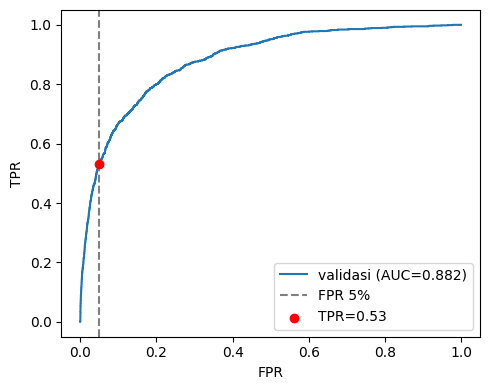

In [38]:
val_scores = best_pipe.predict_proba(X_val)[:, 1]
tpr_val, fpr_val, threshold = tpr_at_fpr(y_val, val_scores)

test_scores = best_pipe.predict_proba(X_test)[:, 1]
flag_test = test_scores >= threshold
tpr_test = float(flag_test[y_test.to_numpy() == 1].mean())
fpr_test = float(flag_test[y_test.to_numpy() == 0].mean())

print(f"VALIDASI (bulan {VAL_MONTHS}): TPR@FPR5% = {tpr_val:.3f} (FPR sebenarnya {fpr_val:.3f}), threshold = {threshold:.5f}")
print(f"UJI      (bulan {TEST_MONTHS}): TPR = {tpr_test:.3f}, FPR = {fpr_test:.3f} dengan threshold yang sama")
print(f"Pengajuan yang tertandai di uji: {flag_test.mean():.2%} (beban verifikasi manual)")

fpr_c, tpr_c, _ = roc_curve(y_val, val_scores)
plt.figure(figsize=(5, 4))
plt.plot(fpr_c, tpr_c, label=f"validasi (AUC={roc_auc_score(y_val, val_scores):.3f})")
plt.axvline(TARGET_FPR, color="gray", ls="--", label="FPR 5%")
plt.scatter([fpr_val], [tpr_val], color="red", zorder=3, label=f"TPR={tpr_val:.2f}")
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(); plt.tight_layout()
plt.savefig(OUT_DIR / "roc_validasi.png", dpi=120)
plt.show()

## 6. Simpan model dan muat ulang
File `model/baf_model.joblib` berisi Pipeline lengkap, threshold, dan daftar fitur. Menerima tabel mentah (kolom sama seperti `Base.csv`).

In [39]:
artifact = {
    "pipeline": best_pipe,
    "threshold": threshold,
    "feature_cols": feature_cols,
    "target_fpr": TARGET_FPR,
    "config_name": best_name,
    "data_source": DATA_SOURCE,
}
joblib.dump(artifact, OUT_DIR / "baf_model.joblib", compress=3)

metrics = {
    "data_source": DATA_SOURCE,
    "config": best_name,
    "train_months": TRAIN_MONTHS, "val_months": VAL_MONTHS, "test_months": TEST_MONTHS,
    "threshold": threshold,
    "val_tpr_at_fpr5": tpr_val, "val_fpr": fpr_val,
    "val_roc_auc": float(roc_auc_score(y_val, val_scores)),
    "val_pr_auc": float(average_precision_score(y_val, val_scores)),
    "test_tpr_at_val_threshold": tpr_test, "test_fpr_at_val_threshold": fpr_test,
    "n_train": int(len(y_train)), "n_val": int(len(y_val)), "n_test": int(len(y_test)),
}
(OUT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")

# ---- muat ulang dan cek hasilnya identik ----
loaded = joblib.load(OUT_DIR / "baf_model.joblib")
skor_ulang = loaded["pipeline"].predict_proba(df.loc[is_va, loaded["feature_cols"]])[:, 1]
assert np.allclose(skor_ulang, val_scores), "skor model yang dimuat ulang berbeda"
print("Model tersimpan dan bisa dimuat ulang. Selisih skor maksimum:", float(np.abs(skor_ulang - val_scores).max()))


def skor_pengajuan(df_baru):
    # df_baru: tabel mentah berkolom seperti BAF. Mengembalikan skor dan keputusan tandai/tidak.
    s = loaded["pipeline"].predict_proba(df_baru[loaded["feature_cols"]])[:, 1]
    return pd.DataFrame({"skor_fraud": s, "tandai": s >= loaded["threshold"]}, index=df_baru.index)


print(skor_pengajuan(df.loc[is_te].head(5)))

Model tersimpan dan bisa dimuat ulang. Selisih skor maksimum: 0.0
        skor_fraud  tandai
397039    0.438120    True
397040    0.000719   False
397041    0.000942   False
397042    0.000863   False
397043    0.003723   False


In [40]:
# Untuk Isi tabel skor di README.md .
readme = Path("README.md")
mulai, akhir = "<!-- SKOR_START -->", "<!-- SKOR_END -->"
if readme.exists() and mulai in readme.read_text(encoding="utf-8"):
    teks = readme.read_text(encoding="utf-8")
    peringatan = ("> **DATA SINTETIS - bukan hasil pada BAF asli.**\n\n" if DATA_SOURCE == "SINTETIS" else "")
    blok = (peringatan
            + "| Ukuran | Nilai |\n|---|---|\n"
            + f"| Sumber data | {DATA_SOURCE} |\n"
            + f"| Konfigurasi terpilih | {best_name} |\n"
            + f"| **TPR @ FPR 5% (validasi, bulan {VAL_MONTHS[0]})** | **{tpr_val:.1%}** |\n"
            + f"| ROC-AUC / PR-AUC validasi | {metrics['val_roc_auc']:.3f} / {metrics['val_pr_auc']:.3f} |\n"
            + f"| Threshold skor | {threshold:.5f} |\n"
            + f"| Uji bulan {TEST_MONTHS[0]} (threshold dibekukan): TPR / FPR | {tpr_test:.1%} / {fpr_test:.1%} |\n")
    baru = teks.split(mulai)[0] + mulai + "\n" + blok + akhir + teks.split(akhir)[1]
    readme.write_text(baru, encoding="utf-8")
    print("README.md diperbarui dengan skor run ini.")

## 7. Unduh hasil (Colab)
Folder `model/` hilang saat sesi Colab berakhir,

In [41]:
import shutil
if Path("README.md").exists():
    shutil.copy("README.md", OUT_DIR / "README.md")
shutil.make_archive("hasil_model", "zip", OUT_DIR)
try:
    from google.colab import files
    files.download("hasil_model.zip")
except ImportError:
    print("Bukan Colab: hasil ada di folder", OUT_DIR, "dan arsip hasil_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Kesimpulan: Deteksi Penipuan Pembukaan Rekening
# Gambaran singkat

Bank menerima banyak pengajuan rekening, dan sekitar 1 dari 100 adalah penipuan. Model ini memberi skor pada setiap pengajuan baru: makin tinggi skornya, makin mirip pola penipuan. Pengajuan yang skornya melewati batas tertentu ditandai untuk diperiksa manual oleh tim risiko.

Output notebook
Setiap pengajuan mendapat skor 0 sampai 1 dan keputusan "tandai" atau "tidak".
Batas skornya 0,03. Contoh dari notebook: satu pengajuan skornya 0,44 sehingga ditandai, sedangkan pengajuan lain skornya 0,0007 sehingga dianggap aman.
Model disimpan sebagai file baf_model.joblib, jadi bisa dipakai lagi tanpa melatih ulang.
Metode

Model belajar dari pengajuan masa lalu yang sudah diketahui mana yang penipuan dan mana yang jujur. Ia mempelajari pola khas penipu, misalnya data yang kosong, kemiripan nama dan email, serta kecepatan pengajuan. Teknik yang dipakai adalah gradient boosting, yaitu banyak aturan sederhana yang disusun berurutan, tiap aturan memperbaiki kesalahan aturan sebelumnya. Data yang kosong tidak dibuang, karena kosongnya data itu sendiri bisa menjadi petunjuk.

Alasan memilih metode ini
Cocok untuk data berbentuk tabel seperti formulir pengajuan.
Bisa menangani data kosong dan kolom berupa kategori tanpa banyak penyiapan.
Cepat dijalankan untuk ratusan ribu pengajuan.
Tiga versi pengaturan model dicoba, dan hasilnya hampir sama (52,6% sampai 53,0%), jadi hasilnya tidak bergantung pada pengaturan tertentu.

### Tabel Pembagian Data Berdasarkan Waktu

| Bagian | Bulan | Fungsi |
| :--- | :--- | :--- |
| **Latihan** | 0-1 | Model belajar mengenali pola penipuan |
| **Validasi** | 2 | Memilih pengaturan model terbaik dan menentukan batas skor (*threshold*) |
| **Uji Akhir** | 3 | Memeriksa apakah batas skor tersebut masih berlaku dan efektif pada data baru |

Di dunia nyata, model selalu menilai pengajuan di masa depan. Kalau data dibagi acak, model seolah "mengintip" bulan yang seharusnya belum ia kenal, dan hasilnya terlihat terlalu bagus.

Skor di data validasi

Model menangkap 53 dari setiap 100 penipu, sementara nasabah jujur yang ikut tertandai dibatasi 5%. Ini angka resmi yang dilaporkan (TPR pada FPR 5% = 53,0%).

Gambaran nyatanya, dari 10.000 pengajuan (sekitar 87 di antaranya penipu):

Model menandai sekitar 540 pengajuan.
Dari situ, sekitar 46 penipu sungguhan tertangkap dan sekitar 500 nasabah jujur ikut tertandai.
Sekitar 41 penipu lolos.

Jadi tidak semua yang ditandai itu penipu: hanya sekitar 1 dari 12. Tandanya adalah kecurigaan, bukan bukti, dan tim risiko tetap perlu memeriksa.

Catatan penting
Hasil bulan 3 lebih longgar dari harapan. Dengan batas skor yang sama, model menangkap 68 dari 100 penipu, tetapi menandai 8,6% nasabah jujur, bukan 5%. Pola pengajuan berubah dari bulan ke bulan, jadi batas skor perlu dihitung ulang berkala dengan data terbaru.
Hampir separuh penipu masih lolos (47%). Model ini alat bantu, bukan pengganti pemeriksaan manusia.
Usia dan pendapatan ikut dipakai. Apakah itu boleh adalah keputusan kebijakan bank, bukan keputusan teknis.